# EMQA_L1_mix_ro_annual

**Romania's electricity generation mix by source**

Energy Markets Quantitative Analysis (EMQA), Lecture 1 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L1/EMQA_L1_mix_ro_annual/EMQA_L1_mix_ro_annual.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

Annual Romanian electricity generation by source (hydro, nuclear, coal, gas, wind, solar, biomass) in TWh for the full years, with load as a black bar, and the shares of each source in January to the cut-off month of the current and the previous year over the hours reported in both years. Energy is summed over reported hours; coverage is reported.

**Data:** 2015-2025 full years (left); Jan-Oct 2025 and 2026, hours reported in both years (right); cut-off 2026-10-31. **Source:** energy-charts.info (Fraunhofer ISE); ENTSO-E (Transelectrica data for Romania).

The numbers printed below are those on the slide; the tag `[key]` is their name in `lectures/L1/L1_numbers.json`.

In [2]:
import json
import urllib.request
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
warnings.filterwarnings('ignore')

# course chart style: transparent background, no gridlines, legend at the bottom outside the axes
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.titlesize': 11.5, 'axes.labelsize': 11,
    'legend.fontsize': 10.5, 'legend.frameon': False, 'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c5': '#e87ba4', 'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}   # fixed colour per bidding zone
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
ZONE_LS = {'RO': '-', 'BG': '--', 'HU': '-.', 'DE_LU': ':'}
ZONES = ['RO', 'BG', 'HU', 'DE_LU']
ZONE_NAME = {'RO': 'Romania (OPCOM PZU)', 'BG': 'Bulgaria (IBEX)', 'HU': 'Hungary (HUPX)', 'DE_LU': 'Germany-Luxembourg'}
MON_EN = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
ZONE_SHORT = {'RO': 'RO (OPCOM PZU)', 'BG': 'BG (IBEX)', 'HU': 'HU (HUPX)', 'DE_LU': 'DE-LU (EPEX SPOT)'}


def month_ticks(ax, step=1):
    """Month axis 1..12: every month named, written vertically so it fits."""
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels([MON_EN[m - 1] if (m - 1) % step == 0 else '' for m in range(1, 13)], fontsize=9, rotation=90)


def legend_bottom(fig, ncol=4, y=0.0):
    """One legend centred under the axes, outside the plotting area."""
    handles, labels = [], []
    for ax in fig.axes:
        for h, l_ in zip(*ax.get_legend_handles_labels()):
            if l_ not in labels:
                handles.append(h)
                labels.append(l_)
    if handles:
        fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, y), frameon=False,
                   handlelength=2.0, columnspacing=1.2)


def fl(x, k=4):
    """Round as on the slides."""
    return None if x is None or np.isnan(float(x)) else round(float(x), k)


def d(ts):
    return pd.Timestamp(ts).strftime('%Y-%m-%d')


def show(key, label, value):
    """Print a number of the slide; [key] = its name in lectures/L1/L1_numbers.json."""
    print(f'{label} = {value}   [{key}]')

## Data
Real series from the course repository (see `data/SOURCES.md`), cut at the last complete month; missing values stay missing.

In [3]:
# data cut-off: last complete calendar month common to the Romanian prices and the generation data
_p = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', usecols=['date_cet', 'RO'], parse_dates=['date_cet']).set_index('date_cet')['RO']
_g = pd.read_csv(DATA + 'generation_ro_mw_daily_cet.csv', usecols=['date_cet', 'hydro_run_of_river'],
                 parse_dates=['date_cet']).set_index('date_cet')['hydro_run_of_river']
_last = min(_p.dropna().index.max(), _g.dropna().index.max())
END = pd.Timestamp(((_last + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)).date())
END_UTC = (END + pd.Timedelta(days=1)).tz_localize('Europe/Brussels').tz_convert('UTC')   # end of the CET day, in UTC
Y = END.year
print('data cut-off:', END.date())

# Romanian generation by source and load, hourly mean MW (UTC, interval start)
GH = pd.read_csv(DATA + 'generation_ro_mw_hourly_utc.csv', parse_dates=['timestamp_utc']).set_index('timestamp_utc')
GH = GH.loc[GH.index < END_UTC]

data cut-off: 2026-10-31


## Computation

In [4]:
# source groups: a group is reported in an hour only if all its parts are reported
GRP = {'Hydro': ['hydro_run_of_river', 'hydro_water_reservoir'], 'Coal': ['brown_coal_lignite', 'hard_coal'],
       'Nuclear': ['nuclear'], 'Gas': ['gas'], 'Wind': ['wind_onshore'], 'Solar': ['solar'], 'Biomass': ['biomass']}
yr = GH.index.year
full_years = [y for y in sorted(set(yr)) if y < Y]
mix, cov = {}, {}
for k, cols in GRP.items():
    s = GH[cols].sum(axis=1, min_count=len(cols))
    mix[k] = s.groupby(yr).sum() / 1e6                           # TWh = sum of hourly mean MW x 1 h / 1e6
    cov[k] = s.notna().groupby(yr).mean()                        # share of hours reported
mix, cov = pd.DataFrame(mix), pd.DataFrame(cov)
load_twh = GH['load'].groupby(yr).sum() / 1e6

def lfl_block(cols, y0, y1):
    """Jan..cut-off month of y1 vs the same months of y0, over the hours reported in BOTH years (TWh)."""
    s = GH[cols].sum(axis=1, min_count=len(cols))
    a = s[(s.index.year == y1) & (s.index.month <= END.month)]
    b_ = s[(s.index.year == y0) & (s.index.month <= END.month)]
    A = pd.Series(a.values, index=a.index.strftime('%m-%d %H'))
    B = pd.Series(b_.values, index=b_.index.strftime('%m-%d %H'))
    A, B = A[~A.index.duplicated()], B[~B.index.duplicated()]
    both = pd.concat([A.rename('a'), B.rename('b')], axis=1).dropna()
    return {'ytd': fl(both['a'].sum() / 1e6, 2), 'prev': fl(both['b'].sum() / 1e6, 2),
            'chg': fl((both['a'].sum() / both['b'].sum() - 1) * 100, 1), 'ytd_own': fl(A.sum() / 1e6, 2)}

L = {k: lfl_block(c, Y - 1, Y) for k, c in GRP.items()}
tot_a, tot_b = sum(L[k]['ytd'] for k in GRP), sum(L[k]['prev'] for k in GRP)
for k in GRP:
    L[k]['share_ytd'] = fl(L[k]['ytd'] / tot_a * 100, 1)
    L[k]['share_prev'] = fl(L[k]['prev'] / tot_b * 100, 1)

show('mix.min_cov_full', 'lowest coverage of a source in a full year, %', fl(cov.loc[full_years].min().min() * 100, 1))
for y in [full_years[0], full_years[-1]]:
    show(f'mix.{y}.total_twh', f'generation {y}, TWh', fl(mix.loc[y].sum(), 2))
    show(f'mix.{y}.load_twh', f'load {y}, TWh', fl(load_twh.loc[y], 2))
for k in GRP:
    show(f'mix.lfl.{k}.share_prev', f'{k} share, Jan-{MON_EN[END.month - 1]} {Y - 1}, %', L[k]['share_prev'])
    show(f'mix.lfl.{k}.share_ytd', f'{k} share, Jan-{MON_EN[END.month - 1]} {Y}, %', L[k]['share_ytd'])

lowest coverage of a source in a full year, % = 98.1   [mix.min_cov_full]
generation 2015, TWh = 64.21   [mix.2015.total_twh]
load 2015, TWh = 56.95   [mix.2015.load_twh]
generation 2025, TWh = 47.41   [mix.2025.total_twh]
load 2025, TWh = 53.56   [mix.2025.load_twh]
Hydro share, Jan-Oct 2025, % = 25.7   [mix.lfl.Hydro.share_prev]
Hydro share, Jan-Oct 2026, % = 27.6   [mix.lfl.Hydro.share_ytd]
Coal share, Jan-Oct 2025, % = 14.4   [mix.lfl.Coal.share_prev]
Coal share, Jan-Oct 2026, % = 12.1   [mix.lfl.Coal.share_ytd]
Nuclear share, Jan-Oct 2025, % = 19.8   [mix.lfl.Nuclear.share_prev]
Nuclear share, Jan-Oct 2026, % = 13.5   [mix.lfl.Nuclear.share_ytd]
Gas share, Jan-Oct 2025, % = 19.8   [mix.lfl.Gas.share_prev]
Gas share, Jan-Oct 2026, % = 20.5   [mix.lfl.Gas.share_ytd]
Wind share, Jan-Oct 2025, % = 12.6   [mix.lfl.Wind.share_prev]
Wind share, Jan-Oct 2026, % = 13.9   [mix.lfl.Wind.share_ytd]
Solar share, Jan-Oct 2025, % = 6.8   [mix.lfl.Solar.share_prev]
Solar share, Jan-Oct 2026, % = 

## Chart

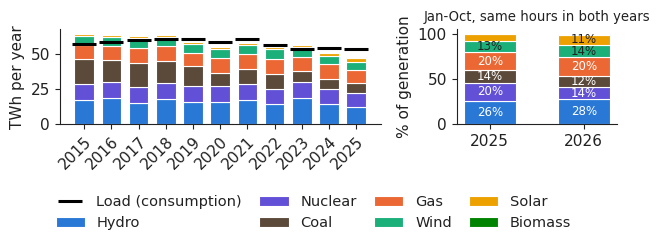

In [5]:
ORDER = ['Hydro', 'Nuclear', 'Coal', 'Gas', 'Wind', 'Solar', 'Biomass']
SCOL = {'Hydro': PAL['RO'], 'Nuclear': PAL['c7'], 'Coal': '#5b4a3a', 'Gas': PAL['DE_LU'], 'Wind': PAL['HU'],
        'Solar': PAL['BG'], 'Biomass': PAL['c6']}
fig, axs = plt.subplots(1, 2, figsize=(6.4, 2.5), gridspec_kw={'width_ratios': [2.0, 1]})
bot = np.zeros(len(full_years))
for k in ORDER:
    axs[0].bar(full_years, mix.loc[full_years, k].values, bottom=bot, color=SCOL[k], label=k, width=0.72,
               edgecolor='white', lw=0.8)
    bot += mix.loc[full_years, k].values
axs[0].plot(full_years, load_twh.loc[full_years], 'k_', ms=17, mew=2.2, label='Load (consumption)')
axs[0].set_ylabel('TWh per year')
axs[0].set_xticks(full_years)
axs[0].set_xticklabels([str(y) for y in full_years], rotation=45, ha='right', rotation_mode='anchor')
sh = pd.DataFrame({0: [L[k]['share_prev'] for k in ORDER], 1: [L[k]['share_ytd'] for k in ORDER]}, index=ORDER)
bot = np.zeros(2)
for k in ORDER:
    axs[1].bar([0, 1], sh.loc[k].values, bottom=bot, color=SCOL[k], width=0.55, edgecolor='white', lw=0.8)
    for i in range(2):
        if sh.loc[k].values[i] >= 9:          # label only segments tall enough for the text; dark text on light colours
            axs[1].text(i, bot[i] + sh.loc[k].values[i] / 2, f'{sh.loc[k].values[i]:.0f}%', ha='center', va='center',
                        fontsize=8.5, color='#222222' if k in ('Solar', 'Wind') else 'white')
    bot += sh.loc[k].values
axs[1].set_xticks([0, 1])
axs[1].set_xticklabels([str(Y - 1), str(Y)])
axs[1].set_ylabel('% of generation')
axs[1].set_title(f'Jan-{MON_EN[END.month - 1]}, same hours in both years', fontsize=9.5)
legend_bottom(fig, ncol=4)
fig.tight_layout(rect=(0, 0.22, 1, 1))
plt.savefig('mix_ro_annual.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()